# IPP Practical File 2

Swanand Wirkar 20251051 BDA

## Problem Statement

Problem 5: Texture-Based Segmentation using GLCM Features
Load a synthetic or natural multi-texture image. Extract local GLCM contrast, energy and homogeneity, then segment into k = 3 clusters. Observe how features affect segmentation quality.

D:\Ananconda\envs\myenv\lib\site-packages\joblib\externals\loky\backend\context.py:110: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "D:\Ananconda\envs\myenv\lib\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
  File "D:\Ananconda\envs\myenv\lib\subprocess.py", line 505, in run
    with Popen(*popenargs, **kwargs) as process:
  File "D:\Ananconda\envs\myenv\lib\subprocess.py", line 951, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "D:\Ananconda\envs\myenv\lib\subprocess.py", line 1436, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


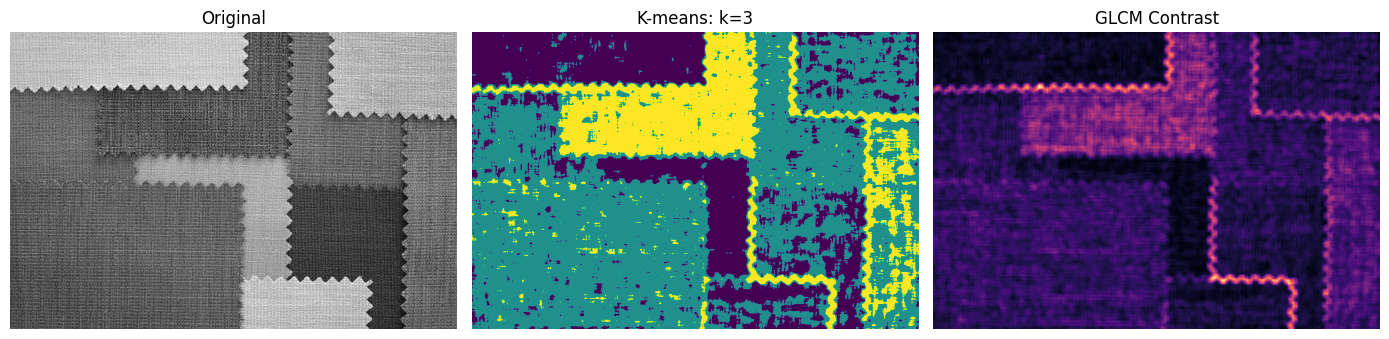

Mean local features — contrast: 2.637723445892334 energy: 0.2674052119255066 homogeneity: 0.5268792510032654
Contrast measures local gray-level variation; energy is high for concentrated, regular patterns; homogeneity is high when neighbouring values are similar. Standardization prevents numerical scale from dominating K-means. Local windows blur boundaries, and distinct materials with similar texture statistics may share a cluster. This pixel-wise GLCM method can be slow on large images; resize for testing.


In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from skimage.feature import graycomatrix, graycoprops

image = cv2.imread("textures.jpg", cv2.IMREAD_GRAYSCALE)
if image is None:
    raise FileNotFoundError("Place a multi-texture image named texture_image.jpg in the notebook folder.")
levels=16; q=(image.astype(np.uint16)*levels//256).astype(np.uint8)
window=9; pad=window//2; padded=cv2.copyMakeBorder(q,pad,pad,pad,pad,cv2.BORDER_REFLECT)
features=np.zeros((image.shape[0],image.shape[1],3),np.float32)
for y in range(image.shape[0]):
    for x in range(image.shape[1]):
        patch=padded[y:y+window,x:x+window]
        glcm=graycomatrix(patch,distances=[1],angles=[0,np.pi/4,np.pi/2,3*np.pi/4],levels=levels,symmetric=True,normed=True)
        features[y,x,0]=np.mean(graycoprops(glcm,"contrast"))
        features[y,x,1]=np.mean(graycoprops(glcm,"energy"))
        features[y,x,2]=np.mean(graycoprops(glcm,"homogeneity"))
X=features.reshape(-1,3); mu=X.mean(axis=0); sd=X.std(axis=0); sd[sd==0]=1; X=(X-mu)/sd
labels=KMeans(n_clusters=3,random_state=42,n_init=10).fit_predict(X).reshape(image.shape)
fig,ax=plt.subplots(1,3,figsize=(14,5)); ax[0].imshow(image,cmap="gray"); ax[0].set_title("Original"); ax[1].imshow(labels,cmap="viridis"); ax[1].set_title("K-means: k=3"); ax[2].imshow(features[:,:,0],cmap="magma"); ax[2].set_title("GLCM Contrast")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
print("Mean local features — contrast:",float(features[:,:,0].mean()),"energy:",float(features[:,:,1].mean()),"homogeneity:",float(features[:,:,2].mean()))
print("Contrast measures local gray-level variation; energy is high for concentrated, regular patterns; homogeneity is high when neighbouring values are similar. Standardization prevents numerical scale from dominating K-means. Local windows blur boundaries, and distinct materials with similar texture statistics may share a cluster. This pixel-wise GLCM method can be slow on large images; resize for testing.")